# 03 - Model Evaluation (Decision Tree, KNN, SVM)
**DS 301 Midterm Project - Predicting Machine Failure Using Machine Learning**

**Role:** Student 3 - Model Evaluation

**Paper:** *Predictive Maintenance of Armoured Vehicles using Machine Learning Approaches* (Sengupta, Mehta, Rana, 2023, arXiv:2307.14453)

This notebook evaluates the predictions made in `02_model_training.ipynb` (paper mode, **no SMOTE**).
It does **not** train any model. It only reads:

- `reports/predictions_paper.csv` - true labels + predictions of 3 models on the same 3,000 test samples
- `reports/knn_cv_results.csv` - 5-fold CV results for K = 3, 5, 7, 9

Outputs (saved by this notebook):

- `reports/metrics_paper.csv` - metric table for all models
- `reports/paper_comparison.csv` - our results vs. the paper's Table III
- `reports/figures/*.png` - confusion matrices and comparison charts

Run order: `python preprocess.py --mode paper` -> `02_model_training.ipynb` -> **this notebook**.

## 1. Setup

In [1]:
# [Purpose] Import libraries and set the working folder to the project root (same as notebook 02)
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)

sns.set_theme(style="whitegrid")
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
print("Working folder:", os.getcwd())

Working folder: /home/claude/eval/repo


## 2. Load predictions and check them
Every model predicted on the **same** `X_test` (70:30 stratified split, `random_state=42`), so the rows line up with `y_test`.

In [2]:
# [Purpose] Load the predictions file and run basic checks (row count, missing values, only 0/1 values)
pred = pd.read_csv("reports/predictions_paper.csv")

MODELS = {
    "Decision Tree": "y_pred_decision_tree",
    "KNN (K=5)": "y_pred_knn",
    "SVM (RBF)": "y_pred_svm",
}
y_true = pred["y_test"]

print("Shape:", pred.shape)
print("Missing values:", pred.isna().sum().sum())
print("Only 0/1 values:", set(np.unique(pred.values)) <= {0, 1})
print(f"Test failures: {y_true.sum()} of {len(y_true)} ({y_true.mean():.2%})")

Shape: (3000, 4)
Missing values: 0
Only 0/1 values: True
Test failures: 102 of 3000 (3.40%)


## 3. Why accuracy is not enough
Only about 3.4% of the test samples are failures. A "model" that **always predicts no failure** already gets very high accuracy.
We add this **majority-class baseline** so every model can be compared against it.

In [3]:
# [Purpose] Add a baseline that always predicts 'no failure' (0)
pred["y_pred_always_0"] = 0
ALL_MODELS = {**MODELS, "Baseline: always 0": "y_pred_always_0"}

baseline_acc = accuracy_score(y_true, pred["y_pred_always_0"])
print(f"Accuracy of always predicting 'no failure': {baseline_acc:.2%}")

Accuracy of always predicting 'no failure': 96.60%


## 4. Metrics for every model
Main metrics are for the **failure class (1)**, because catching failures is the goal of predictive maintenance.

- **Recall** - of all real failures, how many did we catch? (missed failures = costly breakdowns)
- **Precision** - of all failure alarms, how many were real? (false alarms = unnecessary maintenance)
- **F1** - balance of precision and recall
- **Specificity** - of all normal machines, how many were correctly called normal?
- **Balanced accuracy** - average of recall and specificity (not fooled by imbalance)

In [4]:
# [Purpose] Calculate metrics for each model, combine them into one table, and save as CSV
rows = []
for name, col in ALL_MODELS.items():
    y_pred = pred[col]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    })

metrics = pd.DataFrame(rows).set_index("model").round(4)
metrics.to_csv("reports/metrics_paper.csv")
metrics

,accuracy,precision,recall,f1,specificity,balanced_accuracy,TP,FN,FP,TN
model,,,,,,,,,,
Decision Tree,0.9750,0.6134,0.7157,0.6606,0.9841,0.8499,73,29,46,2852
KNN (K=5),0.9687,0.6111,0.2157,0.3188,0.9952,0.6054,22,80,14,2884
SVM (RBF),0.9660,0.0000,0.0000,0.0000,1.0000,0.5000,0,102,0,2898
Baseline: always 0,0.9660,0.0000,0.0000,0.0000,1.0000,0.5000,0,102,0,2898


### 4.1 Classification reports (per class)

In [5]:
# [Purpose] Check precision / recall / F1 for each class (0 = no failure, 1 = failure)
for name, col in MODELS.items():
    print(f"===== {name} =====")
    print(classification_report(y_true, pred[col], labels=[0, 1],
                                target_names=["No failure (0)", "Failure (1)"],
                                digits=3, zero_division=0))

===== Decision Tree =====
                precision    recall  f1-score   support

No failure (0)      0.990     0.984     0.987      2898
   Failure (1)      0.613     0.716     0.661       102

      accuracy                          0.975      3000
     macro avg      0.802     0.850     0.824      3000
  weighted avg      0.977     0.975     0.976      3000

===== KNN (K=5) =====
                precision    recall  f1-score   support

No failure (0)      0.973     0.995     0.984      2898
   Failure (1)      0.611     0.216     0.319       102

      accuracy                          0.969      3000
     macro avg      0.792     0.605     0.651      3000
  weighted avg      0.961     0.969     0.961      3000

===== SVM (RBF) =====
                precision    recall  f1-score   support

No failure (0)      0.966     1.000     0.983      2898
   Failure (1)      0.000     0.000     0.000       102

      accuracy                          0.966      3000
     macro avg      0.483 

## 5. Confusion matrices

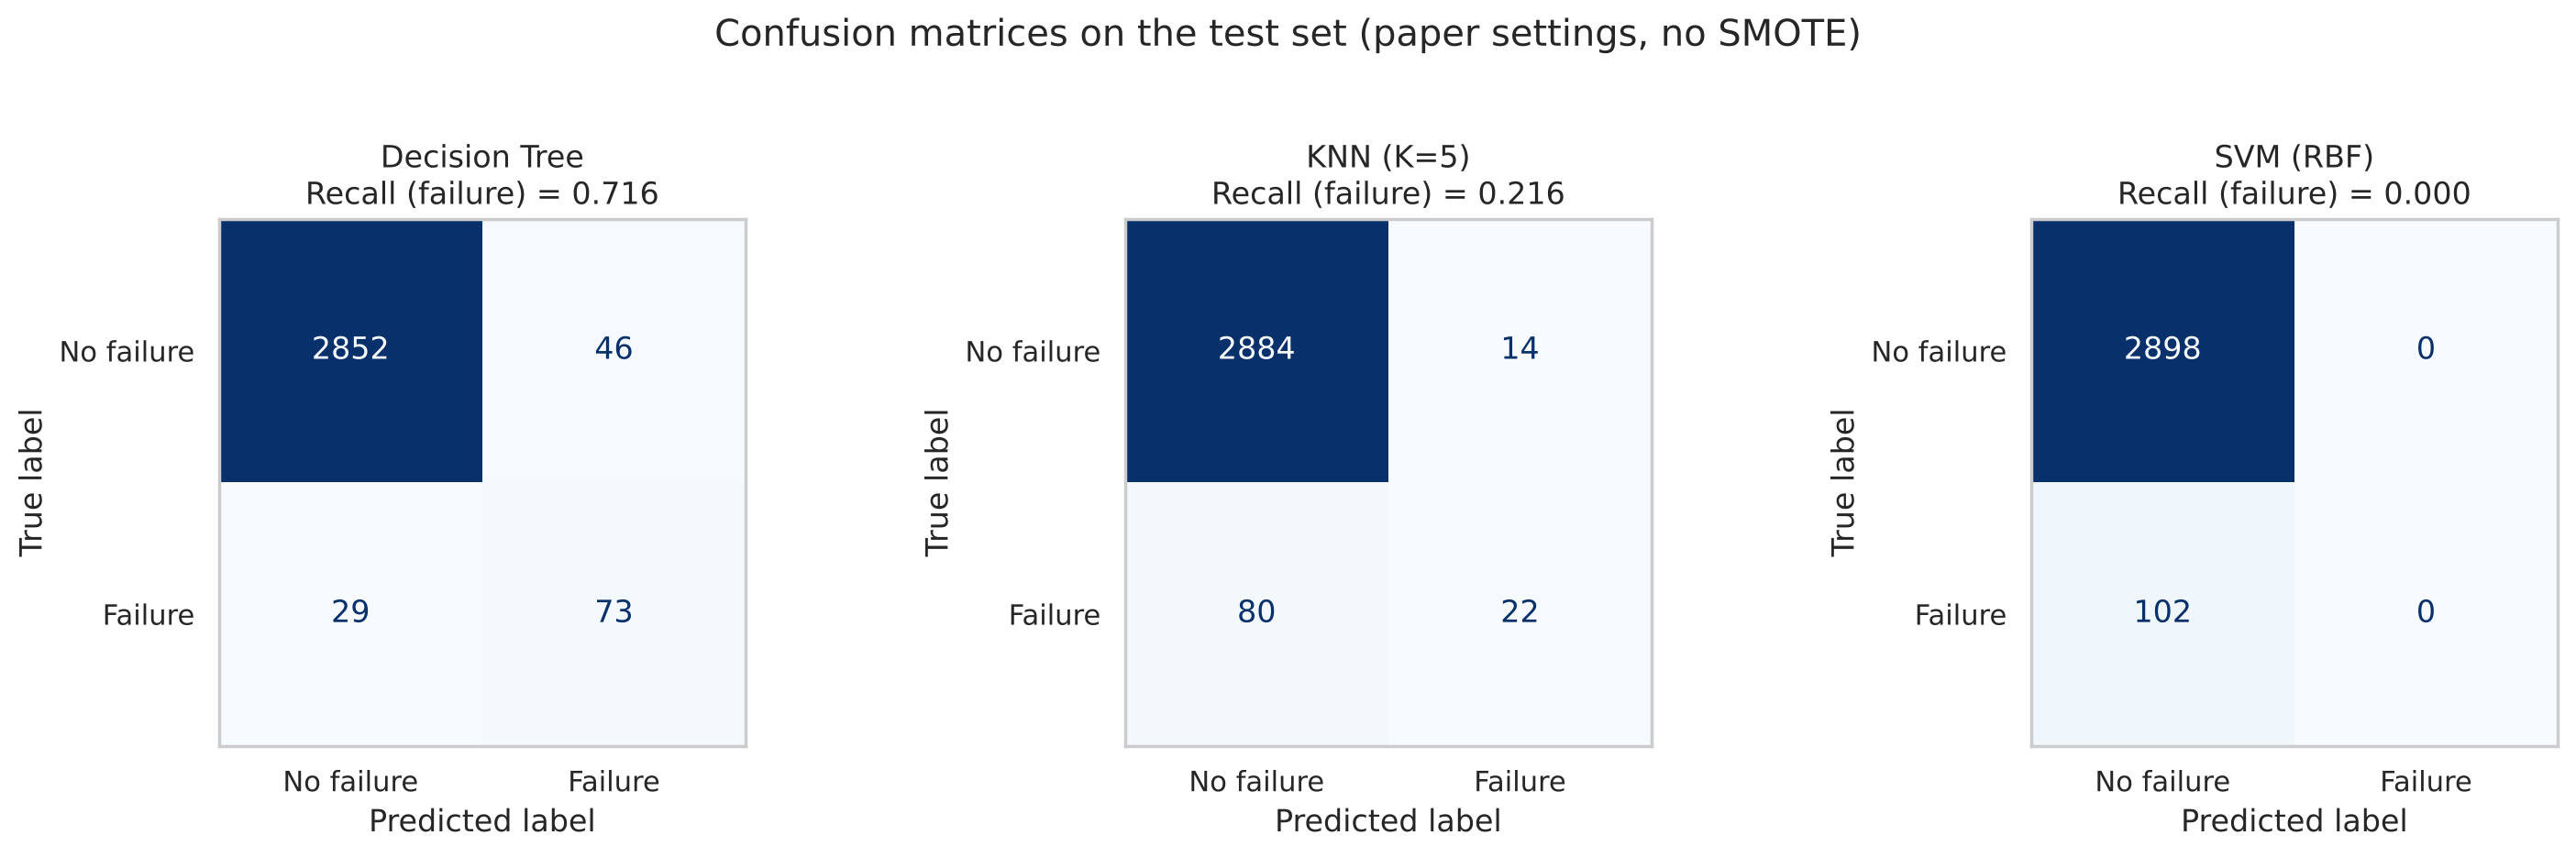

In [6]:
# [Purpose] Compare the confusion matrices of the 3 models in one figure and save it
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, col) in zip(axes, MODELS.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred[col], labels=[0, 1],
        display_labels=["No failure", "Failure"],
        cmap="Blues", colorbar=False, ax=ax)
    r = metrics.loc[name, "recall"]
    ax.set_title(f"{name}\nRecall (failure) = {r:.3f}")
    ax.grid(False)
plt.suptitle("Confusion matrices on the test set (paper settings, no SMOTE)", y=1.03)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrices_paper.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Compare models visually

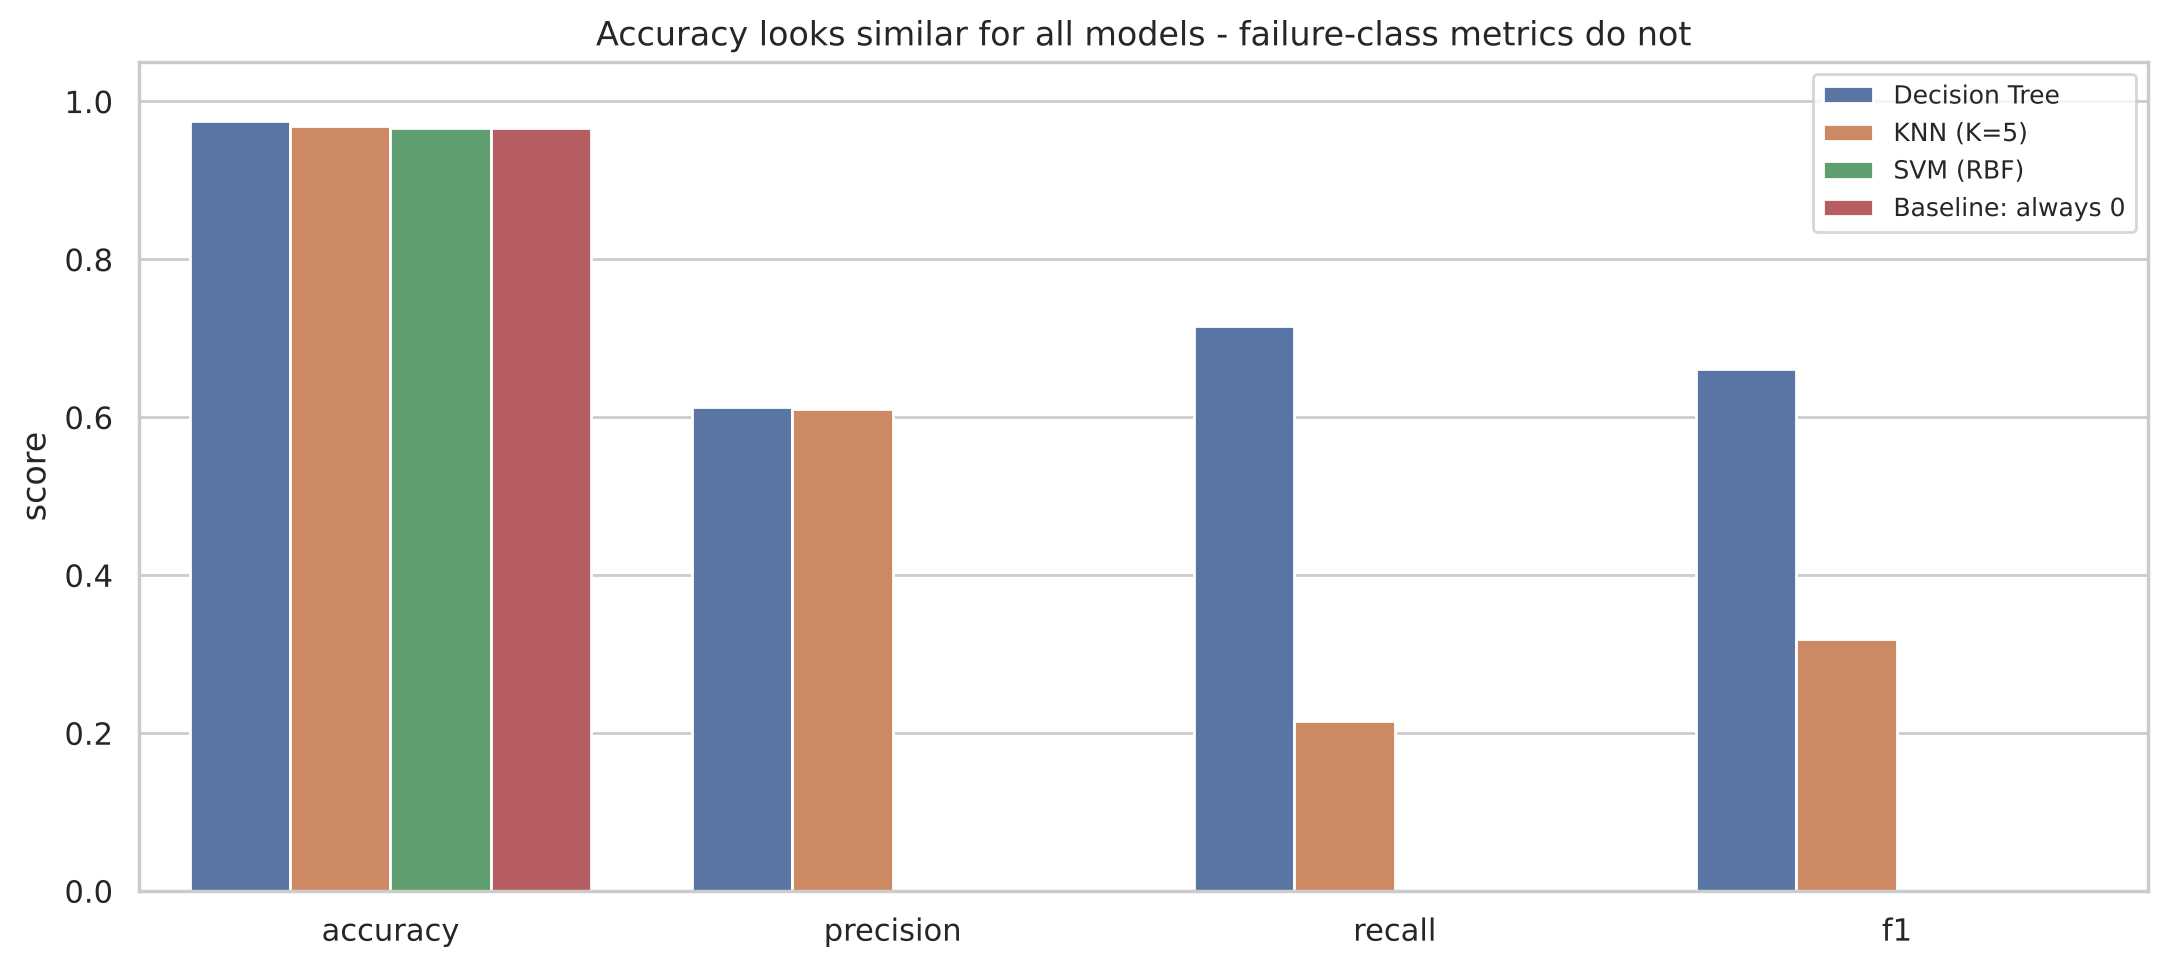

In [7]:
# [Purpose] Compare accuracy and failure-class metrics (precision / recall / F1) in a bar chart
plot_df = (metrics[["accuracy", "precision", "recall", "f1"]]
           .reset_index().melt(id_vars="model", var_name="metric", value_name="score"))

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="metric", y="score", hue="model", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Accuracy looks similar for all models - failure-class metrics do not")
ax.set_xlabel("")
ax.legend(title="", loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/metric_comparison_paper.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Comparison with the paper (Table III)
Values below are copied from **Table III** of the paper. The paper does not report SVM results (SVM appears only in Table II with hyperparameters), so SVM is compared with the paper's **Dummy Classifier** row only as a reference.

Important differences between the paper and our run:

| | Paper | Ours (this notebook) |
|---|---|---|
| Split | 70:30 | 70:30 stratified, `random_state=42` |
| Training failures | 240 | 237 |
| SMOTE on training data | Yes (240 -> 6,760 failures) | **No** |
| KNN neighbors | not reported | K = 5 |

So our numbers are **"paper settings without SMOTE"**, not a full reproduction.

In [8]:
# [Purpose] Compare our results with the paper's Table III (AUC excluded: no probability scores yet)
paper = pd.DataFrame({
    "model": ["Decision Tree", "KNN (K=5)", "Baseline: always 0"],
    "paper_row": ["Decision Tree Classifier", "K Neighbors Classifier", "Dummy Classifier"],
    "accuracy": [0.9810, 0.9741, 0.9676],
    "precision": [0.7103, 0.8194, 0.0],
    "recall": [0.7180, 0.2680, 0.0],
    "f1": [0.7095, 0.3952, 0.0],
}).set_index("model")

cols = ["accuracy", "precision", "recall", "f1"]
comparison = pd.concat(
    {"paper": paper[cols], "ours": metrics.loc[paper.index, cols]}, axis=1)
for c in cols:
    comparison[("diff (ours - paper)", c)] = comparison[("ours", c)] - comparison[("paper", c)]
comparison = comparison.round(4)
comparison.to_csv("reports/paper_comparison.csv")
comparison

paper                              ours            \
                   accuracy precision recall      f1 accuracy precision   
model                                                                     
Decision Tree        0.9810    0.7103  0.718  0.7095   0.9750    0.6134   
KNN (K=5)            0.9741    0.8194  0.268  0.3952   0.9687    0.6111   
Baseline: always 0   0.9676    0.0000  0.000  0.0000   0.9660    0.0000   

                                   diff (ours - paper)                    \
                    recall      f1            accuracy precision  recall   
model                                                                      
Decision Tree       0.7157  0.6606             -0.0060   -0.0969 -0.0023   
KNN (K=5)           0.2157  0.3188             -0.0054   -0.2083 -0.0523   
Baseline: always 0  0.0000  0.0000             -0.0016    0.0000  0.0000   

                            
                        f1  
model                       
Decision Tree      -0.0489  
KNN (K=5)          -0.0764  
Baseline: always 0  0.0000

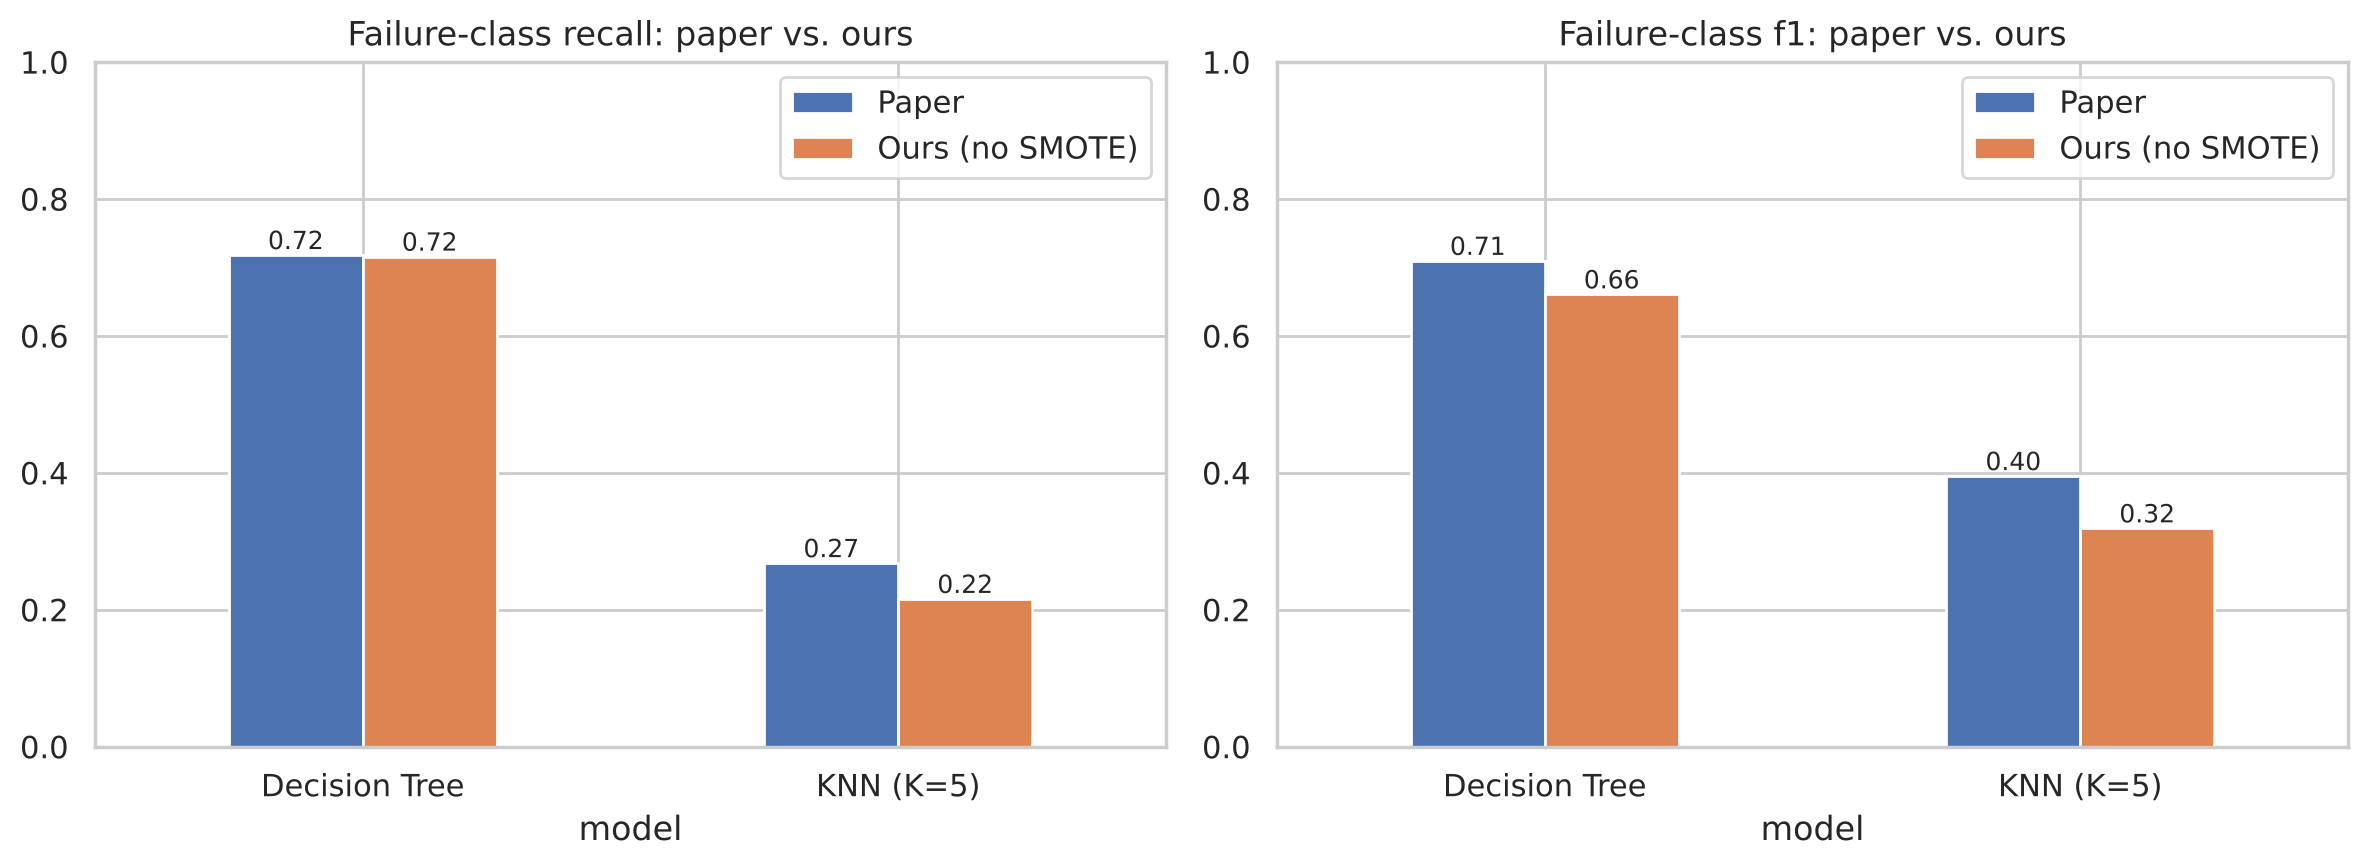

In [9]:
# [Purpose] Plot paper vs. our results for recall and F1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, m in zip(axes, ["recall", "f1"]):
    d = pd.DataFrame({"Paper": paper.loc[["Decision Tree", "KNN (K=5)"], m],
                      "Ours (no SMOTE)": metrics.loc[["Decision Tree", "KNN (K=5)"], m]})
    d.plot(kind="bar", ax=ax, rot=0)
    ax.set_ylim(0, 1)
    ax.set_title(f"Failure-class {m}: paper vs. ours")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/paper_vs_ours.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Error analysis
Which failures are caught, and which are missed by every model?

In [10]:
# [Purpose] Analyze how many of the 102 real failures each model (and combinations of models) caught
fail = pred[pred["y_test"] == 1]
caught_dt = fail["y_pred_decision_tree"] == 1
caught_knn = fail["y_pred_knn"] == 1
caught_svm = fail["y_pred_svm"] == 1

error_summary = pd.Series({
    "Real failures in test": len(fail),
    "Caught by Decision Tree": caught_dt.sum(),
    "Caught by KNN": caught_knn.sum(),
    "Caught by SVM": caught_svm.sum(),
    "Caught by both DT and KNN": (caught_dt & caught_knn).sum(),
    "Caught only by KNN (DT missed)": (~caught_dt & caught_knn).sum(),
    "Caught by at least one model": (caught_dt | caught_knn | caught_svm).sum(),
    "Missed by every model": (~caught_dt & ~caught_knn & ~caught_svm).sum(),
})
error_summary.to_frame("count")

,count
Real failures in test,102
Caught by Decision Tree,73
Caught by KNN,22
Caught by SVM,0
Caught by both DT and KNN,18
Caught only by KNN (DT missed),4
Caught by at least one model,77
Missed by every model,25


In [11]:
# [Purpose] Compare false alarms (false positives): normal samples predicted as failures
normal = pred[pred["y_test"] == 0]
fp_summary = pd.Series({
    "Real normal samples": len(normal),
    "False alarms - Decision Tree": (normal["y_pred_decision_tree"] == 1).sum(),
    "False alarms - KNN": (normal["y_pred_knn"] == 1).sum(),
    "False alarms - SVM": (normal["y_pred_svm"] == 1).sum(),
    "False alarms by both DT and KNN": ((normal["y_pred_decision_tree"] == 1)
                                        & (normal["y_pred_knn"] == 1)).sum(),
})
fp_summary.to_frame("count")

,count
Real normal samples,2898
False alarms - Decision Tree,46
False alarms - KNN,14
False alarms - SVM,0
False alarms by both DT and KNN,2


> **Limitation:** `X_test.csv` is saved without the original row ID (`UDI`), so we cannot link a missed failure back to its failure mode (TWF / HDF / PWF / OSF / RNF) in the raw data.
> If `preprocess.py` also saved `UDI` for the test rows, we could check *which type* of failure each model misses (for example, RNF is random by definition and is expected to be hard to predict).

## 9. KNN: choice of K (cross-validation on training data)

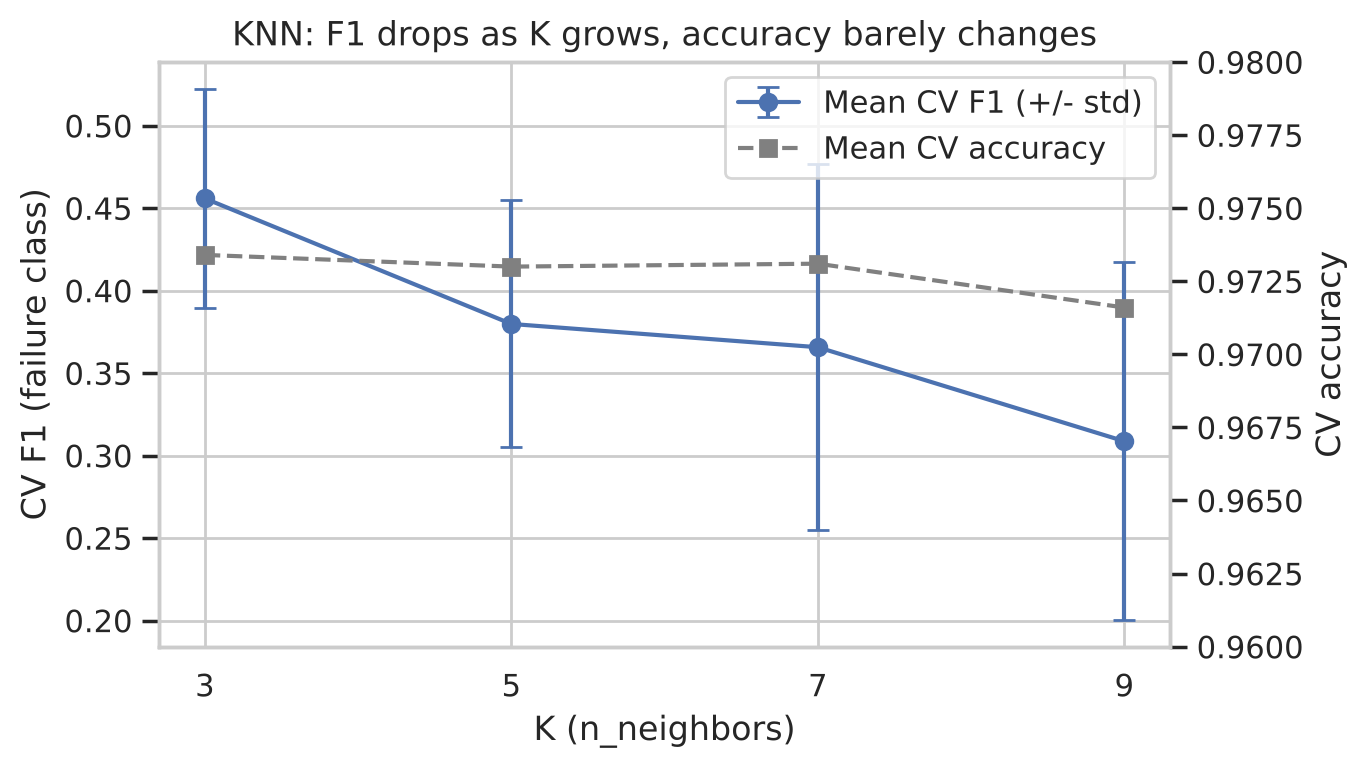

,K,mean_cv_f1,std_cv_f1,mean_cv_accuracy
0,3,0.4559,0.0666,0.9734
1,5,0.3798,0.0749,0.9730
2,7,0.3657,0.1111,0.9731
3,9,0.3087,0.1084,0.9716


In [12]:
# [Purpose] Plot cross-validation F1 / accuracy for each K (results from notebook 02)
knn_cv = pd.read_csv("reports/knn_cv_results.csv")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.errorbar(knn_cv["K"], knn_cv["mean_cv_f1"], yerr=knn_cv["std_cv_f1"],
             marker="o", capsize=4, label="Mean CV F1 (+/- std)")
ax1.set_xlabel("K (n_neighbors)")
ax1.set_ylabel("CV F1 (failure class)")
ax1.set_xticks(knn_cv["K"])
ax2 = ax1.twinx()
ax2.plot(knn_cv["K"], knn_cv["mean_cv_accuracy"], marker="s", color="gray",
         linestyle="--", label="Mean CV accuracy")
ax2.set_ylabel("CV accuracy")
ax2.set_ylim(0.96, 0.98)
ax2.grid(False)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc="upper right")
ax1.set_title("KNN: F1 drops as K grows, accuracy barely changes")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/knn_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()
knn_cv

## 10. ROC AUC and PR AUC (needs predicted probabilities)
The paper reports **AUC**, and our EDA recommends **PR-AUC** for this imbalanced data.
These metrics need **probability scores**, not 0/1 labels. The current `predictions_paper.csv` only has 0/1 labels.

If `02_model_training.ipynb` adds columns named `y_proba_decision_tree`, `y_proba_knn`, `y_proba_svm`
(from `predict_proba(X_test)[:, 1]`, or `decision_function` for SVM), this cell computes them automatically.

In [13]:
# [Purpose] If probability columns exist, compute ROC AUC / PR AUC and save the curves; otherwise print a message
PROBA_COLS = {
    "Decision Tree": "y_proba_decision_tree",
    "KNN (K=5)": "y_proba_knn",
    "SVM (RBF)": "y_proba_svm",
}
available = {n: c for n, c in PROBA_COLS.items() if c in pred.columns}

if not available:
    print("No probability columns found in predictions_paper.csv -> ROC AUC / PR AUC skipped.")
    print("Ask the model-training notebook to save:", list(PROBA_COLS.values()))
else:
    auc_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for name, col in available.items():
        auc_rows.append({"model": name,
                         "roc_auc": roc_auc_score(y_true, pred[col]),
                         "pr_auc": average_precision_score(y_true, pred[col])})
        RocCurveDisplay.from_predictions(y_true, pred[col], name=name, ax=axes[0])
        PrecisionRecallDisplay.from_predictions(y_true, pred[col], name=name, ax=axes[1])
    axes[0].set_title("ROC curve")
    axes[1].axhline(y_true.mean(), color="gray", linestyle="--", label="Random (failure rate)")
    axes[1].set_title("Precision-Recall curve")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/roc_pr_curves_paper.png", dpi=150, bbox_inches="tight")
    plt.show()
    auc_table = pd.DataFrame(auc_rows).set_index("model").round(4)
    auc_table.to_csv("reports/auc_paper.csv")
    display(auc_table)

No probability columns found in predictions_paper.csv -> ROC AUC / PR AUC skipped.
Ask the model-training notebook to save: ['y_proba_decision_tree', 'y_proba_knn', 'y_proba_svm']


## 11. Summary of findings
*(numbers from the cells above; test set = 3,000 samples, 102 failures)*

1. **Accuracy is misleading here.** Always predicting "no failure" gives **96.6%** accuracy. All three models are between 96.6% and 97.5%, so accuracy alone cannot tell them apart.
2. **SVM learned nothing useful.** It predicted *every* sample as normal (recall = 0). Its accuracy is exactly the always-0 baseline. With only ~3.4% failures and no class balancing, the RBF SVM simply ignores the minority class.
3. **Decision Tree is the best model** in our run: it catches about **72%** of failures (recall 0.716, F1 0.661), with 46 false alarms out of 2,898 normal samples.
4. **KNN (K=5) misses most failures** (recall 0.216). Cross-validation shows **K = 3** gives a higher F1 (0.456 vs. 0.380), so K=5 is not the best choice for this task.
5. **Compared with the paper:** our Decision Tree recall (0.716) is almost the same as the paper's (0.718), but our precision and F1 are lower. KNN is also lower than the paper on every metric. A likely reason is that **we have not applied SMOTE yet**, while the paper did.

## 12. Suggested improvements (for the presentation)
- **Apply SMOTE to the training data only** (inside an `imblearn` pipeline) to complete the paper reproduction and re-run this notebook.
- **Use class weights** (`class_weight="balanced"`) for SVM and Decision Tree as a simpler alternative to SMOTE.
- **Choose K by CV F1** (K = 3) instead of the default K = 5.
- **Tune the decision threshold** using predicted probabilities: in maintenance, a missed failure usually costs more than a false alarm, so a lower threshold that raises recall may be preferable.
- **Use the engineered features** (`temp_diff`, `power`, `strain`) from `improved` mode - the EDA showed they separate HDF / PWF / OSF failures much better than the raw features.
- **Save probabilities and test-row IDs** so that ROC-AUC / PR-AUC and failure-mode error analysis become possible.